# EDA: UA Locations Extractions

In [1]:
import os, ast, re
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt

N = 200_000

files = [os.path.join(d, f) for d, _, fs in os.walk('/kaggle/input') for f in fs]
for f in files: print(f)

/kaggle/input/competitions/kse-ua-location-extraction-2026/ru_geo_dataset.csv
/kaggle/input/competitions/kse-ua-location-extraction-2026/README.md
/kaggle/input/competitions/kse-ua-location-extraction-2026/labeling_sample.csv
/kaggle/input/competitions/kse-ua-location-extraction-2026/test.csv
/kaggle/input/competitions/kse-ua-location-extraction-2026/uk_geo_dataset.csv
/kaggle/input/competitions/kse-ua-location-extraction-2026/uk_geo_dataset_processed_v1.parquet


In [ ]:
def find(word):
    return [f for f in files if word in os.path.basename(f).lower() and f.endswith(('.parquet', '.csv'))][0]

def load(path, n=None):
    if path.endswith('.parquet'):
        if n is None:
            return pd.read_parquet(path)
        batch = next(pq.ParquetFile(path).iter_batches(batch_size=n))
        return batch.to_pandas()
    return pd.read_csv(path, nrows=n)

def to_list(x):
    if isinstance(x, str):
        x = ast.literal_eval(x)
    return [tuple(s) for s in x]

uk  = load(find('uk_geo'), N)
ru  = load(find('ru_geo'), N)
lab = load(find('labeling'))
test = load(find('test'))

for name, df in [('uk', uk), ('ru', ru), ('labeling_sample', lab), ('test', test)]:
    print(name, df.shape, list(df.columns))

uk (200000, 5) ['text', 'loc_markers', 'org_markers', 'per_markers', 'is_valid']
ru (200000, 6) ['text', 'loc_markers', 'org_markers', 'per_markers', 'doc_id', 'sent_id']
labeling_sample (26, 3) ['text', 'locations', 'loc_markers']
test (477, 3) ['text_id', 'text', 'locations']


## 1. Приклад даних

In [3]:
lab['loc_markers'] = lab['loc_markers'].apply(to_list)
uk['loc_markers']  = uk['loc_markers'].apply(to_list)
ru['loc_markers']  = ru['loc_markers'].apply(to_list)

row = lab.iloc[0]
print(row['text'])
print(row['loc_markers'])
print([row['text'][a:b] for a, b in row['loc_markers']])

-261.310
[]
[]


## 2. Довжина текстів (у символах і словах)

In [4]:
sets = {'uk': uk, 'ru': ru, 'labeling': lab, 'test': test}
rows = []
for name, df in sets.items():
    ch = df['text'].str.len()
    wd = df['text'].str.split().str.len()
    rows.append({'набір': name, 'рядків': len(df), 'сим. mean': ch.mean(), 'сим. median': ch.median(),
                 'сим. max': ch.max(), 'слів mean': wd.mean(), 'слів max': wd.max()})
pd.DataFrame(rows).round(1)

,набір,рядків,сим. mean,сим. median,сим. max,слів mean,слів max
0,uk,200000,102.2,91.0,255,14.6,50
1,ru,200000,109.3,100.0,714,15.1,102
2,labeling,26,294.4,217.5,1118,42.9,164
3,test,477,395.4,264.0,3682,54.9,509


## 3. Локації: скільки на текст, скільки текстів без локацій

In [5]:
rows = []
for name in ['uk', 'ru', 'labeling']:
    df = sets[name]
    n = df['loc_markers'].str.len()
    rows.append({'набір': name, 'локацій на текст (mean)': n.mean(), 'max': n.max(),
                 '% текстів без локацій': (n == 0).mean() * 100})
pd.DataFrame(rows).round(2)

,набір,локацій на текст (mean),max,% текстів без локацій
0,uk,0.34,13,76.99
1,ru,0.42,49,72.46
2,labeling,1.23,10,38.46


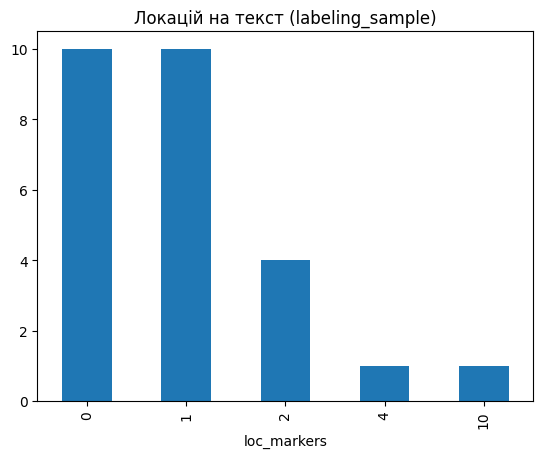

In [ ]:
lab['loc_markers'].str.len().value_counts().sort_index().plot(kind='bar', title='Локацій на текст (labeling_sample)')
plt.show()

## 4. Які локації найчастіші (labeling_sample)

In [7]:
lab['locs'] = lab.apply(lambda r: [r['text'][a:b] for a, b in r['loc_markers']], axis=1)
all_locs = pd.Series([l for ls in lab['locs'] for l in ls])
print('Унікальних:', all_locs.nunique(), 'з', len(all_locs))
print(all_locs.str.lower().value_counts().head(15))
print('Середня довжина локації (слів):', all_locs.str.split().str.len().mean().round(2))

Унікальних: 30 з 32
київщині             2
києва                2
чорнобиль            1
київ                 1
тетерів              1
проспект бандери     1
фастів               1
біла церква          1
бориспіль            1
миронівка            1
яготин               1
баришівка            1
проспекті івасюка    1
хелма                1
києву                1
Name: count, dtype: int64
Середня довжина локації (слів): 1.34


## 5. Мова текстів
Українські літери: і ї є ґ. Російські: ы э ъ ё. Якщо є обидва набори — змішаний текст.

In [8]:
def lang(t):
    t = t.lower()
    u = bool(re.search('[іїєґ]', t))
    r = bool(re.search('[ыэъё]', t))
    if u and r: return 'змішаний'
    if u: return 'укр'
    if r: return 'рос'
    return 'невизначено'

res = pd.DataFrame({name: df['text'].apply(lang).value_counts(normalize=True) * 100
                    for name, df in sets.items()}).round(1)
res

,uk,ru,labeling,test
text,,,,
змішаний,0.1,0.0,NaN,0.2
невизначено,1.3,21.4,3.8,3.4
рос,0.0,78.6,3.8,6.9
укр,98.7,0.0,92.3,89.5


## 6. Латиниця і цифри (адреси)

In [9]:
for name, df in sets.items():
    t = df['text']
    print(f"{name:9s} з латиницею: {t.str.contains('[A-Za-z]').mean()*100:5.1f}%   з цифрами: {t.str.contains(r'\d').mean()*100:5.1f}%")

uk        з латиницею:   6.5%   з цифрами:  21.9%
ru        з латиницею:  14.0%   з цифрами:  28.6%
labeling  з латиницею:  23.1%   з цифрами:  57.7%
test      з латиницею:  31.7%   з цифрами:  58.5%


## Висновки

**1. Розмір наборів.** З `uk` і `ru` взято по 200 000 рядків (підвибірка). Розмічений `labeling_sample` дуже малий: **лише 26 текстів**. У `test` 477 текстів.

**2. Тренувальні дані й тест суттєво відрізняються.**
- Довжина: у `uk`/`ru` текст ≈ 100 символів (≈ 15 слів), у `labeling` ≈ 294, у `test` ≈ 395 символів (≈ 55 слів, максимум 509 слів і 3682 символи). Тест у 3–4 рази довший.
- Цифри: у `uk`/`ru` 22–29 % текстів, у `labeling`/`test` ≈ 58 %.
- Латиниця: у `uk`/`ru` 6,5–14 %, у `labeling`/`test` 23–32 %.
- Тобто тест містить довші, «брудніші» тексти з адресами, цифрами та латинськими назвами, а великі корпуси це майже не покривають.

**3. Дисбаланс класів.** У `uk` 77 % текстів, а в `ru` 72 % без жодної локації. У `labeling` таких лише 38 %. Локацій на текст: 0,34 (`uk`), 0,42 (`ru`), 1,23 (`labeling`). Модель, навчена на великих корпусах, бачитиме надто мало локацій і схилятиметься до тегу `O`, тому recall буде занижений. Це варто компенсувати порогом, вагами класів або відбором текстів з локаціями.

**4. Мова.** `uk` майже повністю українська (98,7 %). У `ru` 78,6 % російських, решта 21 % без характерних літер (короткі тексти). У `labeling`/`test` ≈ 90 % українських, ≈ 4–7 % російських, змішаних майже немає. Український корпус для тесту важливіший за російський.

**5. Самі локації.** Здебільшого це одне слово (в середньому 1,34 слова), але у різних відмінках: `києва`, `києву`, `київщині`, `київ`. Метрика порівнює рядки точно (після нижнього регістру), тому форму слова треба передбачити правильно. Це аргумент за BPE або символьну інформацію. Трапляються й адресні форми: `проспект бандери`, `проспекті івасюка`.